# 🌡️ 11. Disease Prediction Model (Flu / Influenza & Fever-Related Conditions)
**HealConnect AI ML Pipeline — Separate Disease Scope**

This notebook models and evaluates disease diagnosis classification (Flu / Influenza vs Fever-Related Condition vs Normal Baseline) separate from the 12-hour acute hospital deterioration model (Hospital A, B, C).

### 📋 Architecture & Data Scope
```text
HealConnect ML
│
├── Hospital A ─┐
├── Hospital B ─┼── Deterioration Model (12h Acute Deterioration Risk)
├── Hospital C ─┘
│
└── Separate Disease Scope
       ├── Flu / Influenza
       └── Fever-related condition (Viral / High Fever)
```


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
from pathlib import Path
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']


In [2]:
DATA_PATH = Path("../data/cleaned_disease_dataset.csv")
METRICS_PATH = Path("../artifacts/disease_model_v1_metrics.json")
MODEL_PATH = Path("../artifacts/disease_model_v1.joblib")

df = pd.read_csv(DATA_PATH)
print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (15000, 14)


,patient_id,age,gender,temperature_c,heart_rate,spo2_pct,cough_severity,headache_severity,fatigue_score,chills,body_ache,sore_throat,disease_label,disease_condition
0,DIS-1000,63,Female,37.9,95,95.3,3,2,2,1,1,1,1,Flu / Influenza
1,DIS-1001,26,Male,38.5,98,95.6,1,2,3,0,1,0,2,Fever-Related Condition
2,DIS-1002,83,Male,36.5,64,97.2,0,0,0,0,0,0,0,Normal Baseline
3,DIS-1003,72,Female,37.1,62,99.2,0,1,1,0,0,0,0,Normal Baseline
4,DIS-1004,32,Female,39.7,104,94.1,1,3,3,0,1,0,2,Fever-Related Condition


C:\Users\pc\AppData\Local\Temp\ipykernel_17484\1725933653.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="disease_condition", palette=["#10b981", "#3b82f6", "#ef4444"], ax=ax)


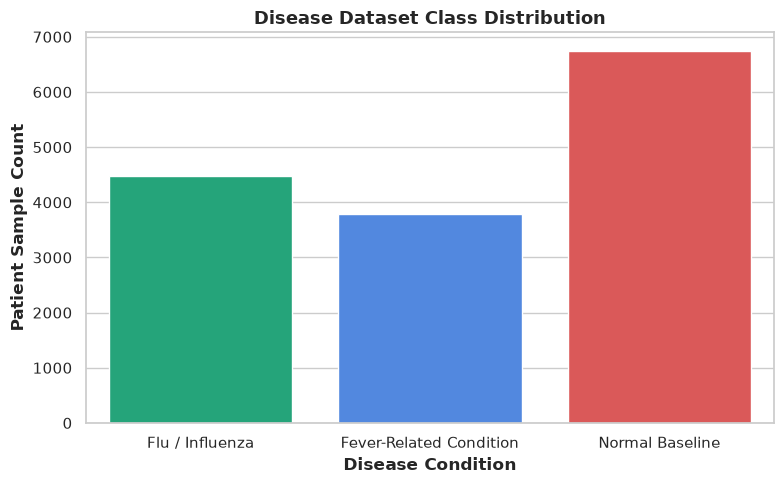

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df, x="disease_condition", palette=["#10b981", "#3b82f6", "#ef4444"], ax=ax)
ax.set_title("Disease Dataset Class Distribution", fontsize=13, fontweight="bold")
ax.set_xlabel("Disease Condition", fontweight="bold")
ax.set_ylabel("Patient Sample Count", fontweight="bold")
plt.tight_layout()
plt.show()


=== DISEASE MODEL PERFORMANCE METRICS ===
Model Version:  v1.0
Algorithm:      RandomForestClassifier (Multi-Class Disease)
Accuracy:       96.53%
Precision:      96.53%
Recall:         96.53%
Weighted F1:    96.53%
Multi-Class ROC-AUC:  99.61%


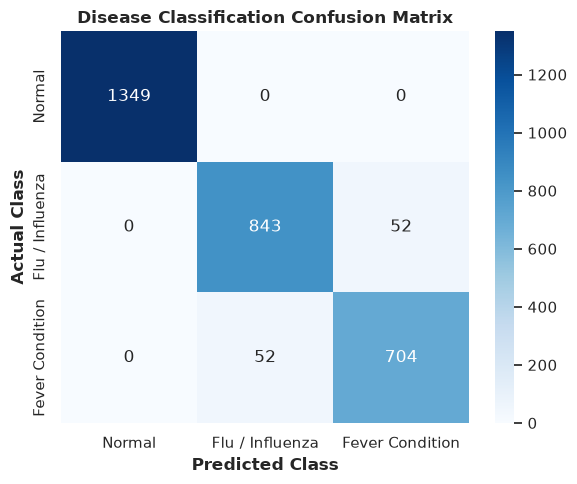

In [4]:
with open(METRICS_PATH, "r") as f:
    metrics = json.load(f)

m = metrics.get("test_metrics", metrics.get("metrics", {}))

print("=== DISEASE MODEL PERFORMANCE METRICS ===")
print("Model Version: ", metrics.get("model_version", "v1.0"))
print("Algorithm:     ", metrics.get("algorithm", "RandomForest"))
print("Accuracy:      ", f"{m['accuracy'] * 100:.2f}%")
print("Precision:     ", f"{m['precision'] * 100:.2f}%")
print("Recall:        ", f"{m['recall'] * 100:.2f}%")
print("Weighted F1:   ", f"{m['f1_score'] * 100:.2f}%")
if "roc_auc" in m:
    print("Multi-Class ROC-AUC: ", f"{m['roc_auc'] * 100:.2f}%")

cm = np.array(metrics["confusion_matrix"])
labels = ["Normal", "Flu / Influenza", "Fever Condition"]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_title("Disease Classification Confusion Matrix", fontweight="bold")
ax.set_ylabel("Actual Class", fontweight="bold")
ax.set_xlabel("Predicted Class", fontweight="bold")
plt.tight_layout()
plt.show()


In [5]:
clf = joblib.load(MODEL_PATH)

sample_patient = pd.DataFrame([{
    "temperature_c": 38.8,
    "heart_rate": 104,
    "spo2_pct": 95.5,
    "cough_severity": 2,
    "headache_severity": 2,
    "fatigue_score": 3,
    "chills": 1,
    "body_ache": 1,
    "sore_throat": 1,
    "age": 34,
    "gender": "Female"
}])

probs = clf.predict_proba(sample_patient)[0]
pred_class = int(np.argmax(probs))
classes = metrics["classes"]

print("=== LIVE SAMPLE INFERENCE ===")
print("Input Vitals: Temp=38.8°C, HR=104, Cough=2, Chills=1, Gender=Female")
print(f"Predicted Diagnosis: {classes[str(pred_class)]}")
print(f"Model Confidence:    {probs[pred_class]*100:.2f}%")


ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- gender
